In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler


In [28]:
iris = sns.load_dataset('iris')
iris.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


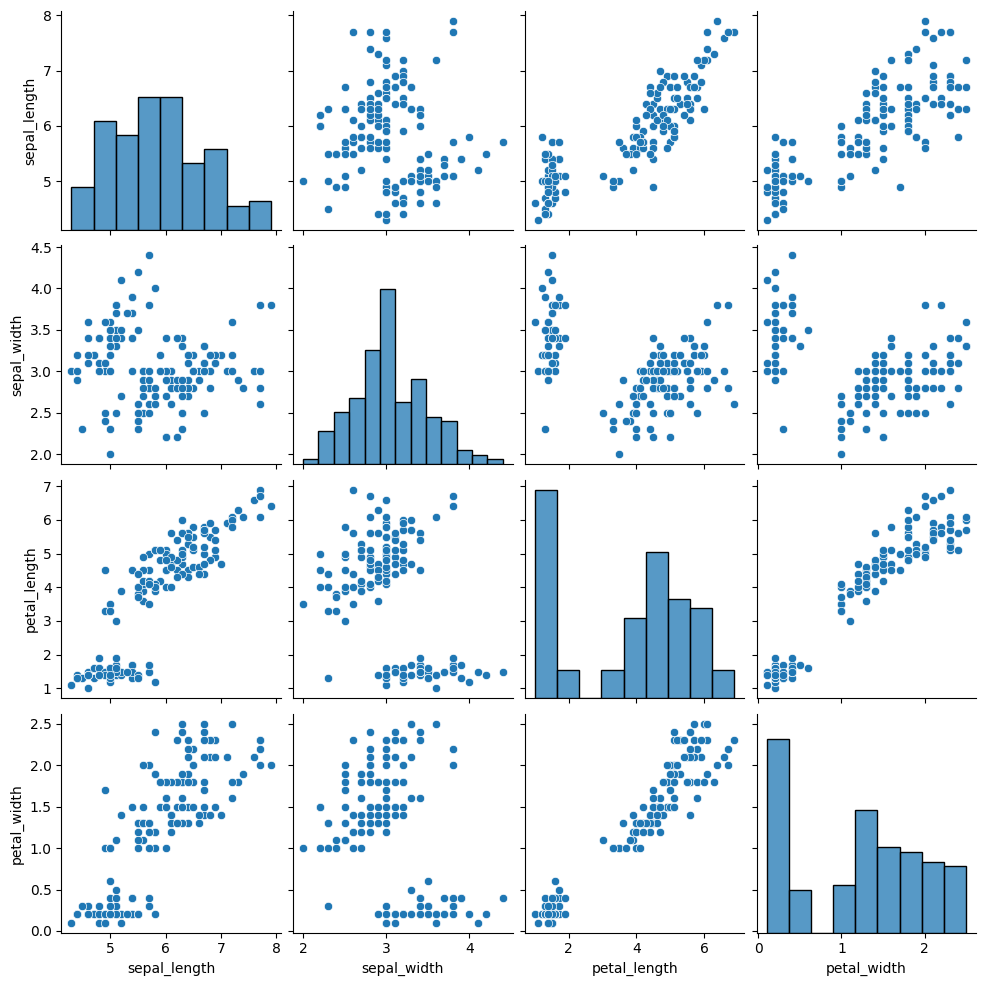

In [29]:
sns.pairplot(iris)

In [30]:
iris.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [31]:
scaler = StandardScaler()
scaled = scaler.fit_transform(
    iris[['sepal_length', 'sepal_width', 'petal_length', 'petal_width']]
)
scaled.T

array([[-9.00681170e-01, -1.14301691e+00, -1.38535265e+00,
        -1.50652052e+00, -1.02184904e+00, -5.37177559e-01,
        -1.50652052e+00, -1.02184904e+00, -1.74885626e+00,
        -1.14301691e+00, -5.37177559e-01, -1.26418478e+00,
        -1.26418478e+00, -1.87002413e+00, -5.25060772e-02,
        -1.73673948e-01, -5.37177559e-01, -9.00681170e-01,
        -1.73673948e-01, -9.00681170e-01, -5.37177559e-01,
        -9.00681170e-01, -1.50652052e+00, -9.00681170e-01,
        -1.26418478e+00, -1.02184904e+00, -1.02184904e+00,
        -7.79513300e-01, -7.79513300e-01, -1.38535265e+00,
        -1.26418478e+00, -5.37177559e-01, -7.79513300e-01,
        -4.16009689e-01, -1.14301691e+00, -1.02184904e+00,
        -4.16009689e-01, -1.14301691e+00, -1.74885626e+00,
        -9.00681170e-01, -1.02184904e+00, -1.62768839e+00,
        -1.74885626e+00, -1.02184904e+00, -9.00681170e-01,
        -1.26418478e+00, -9.00681170e-01, -1.50652052e+00,
        -6.58345429e-01, -1.02184904e+00,  1.40150837e+0

In [32]:
covariance_matrix = np.cov(scaled.T)
covariance_matrix

array([[ 1.00671141, -0.11835884,  0.87760447,  0.82343066],
       [-0.11835884,  1.00671141, -0.43131554, -0.36858315],
       [ 0.87760447, -0.43131554,  1.00671141,  0.96932762],
       [ 0.82343066, -0.36858315,  0.96932762,  1.00671141]])

<Axes: >

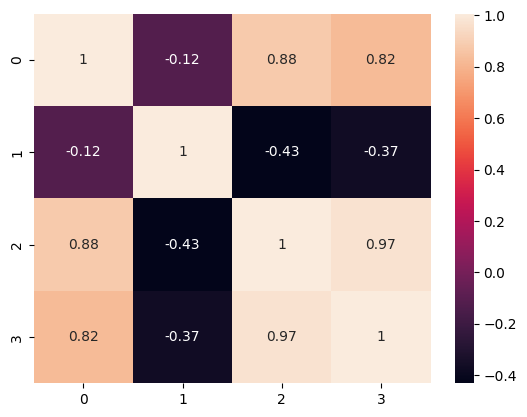

In [33]:
sns.heatmap(covariance_matrix, annot=True)

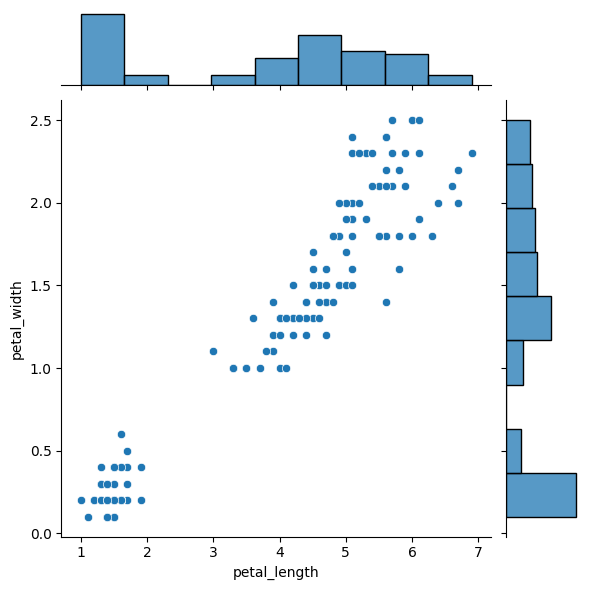

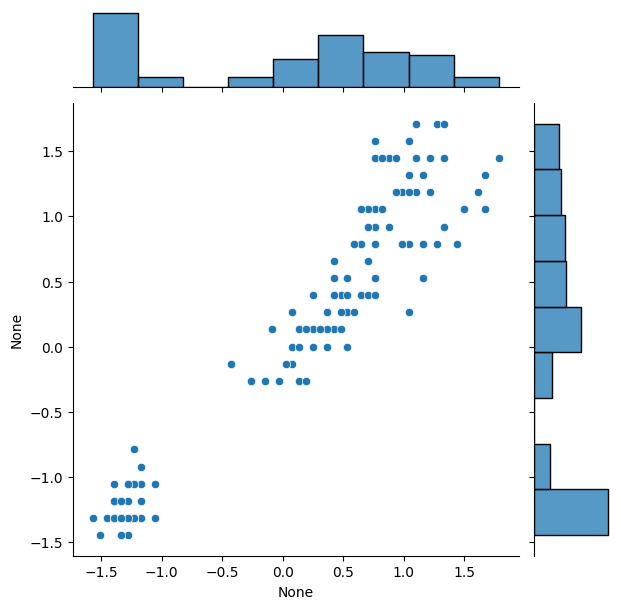

In [34]:
sns.jointplot(x= iris['petal_length'], y=iris['petal_width'])
sns.jointplot(x= scaled[:,2], y=scaled[:,3])

In [35]:
eigen_values, eigen_vectors = np.linalg.eig(covariance_matrix)
eigen_values

array([2.93808505, 0.9201649 , 0.14774182, 0.02085386])

In [36]:
eigen_vectors

array([[ 0.52106591, -0.37741762, -0.71956635,  0.26128628],
       [-0.26934744, -0.92329566,  0.24438178, -0.12350962],
       [ 0.5804131 , -0.02449161,  0.14212637, -0.80144925],
       [ 0.56485654, -0.06694199,  0.63427274,  0.52359713]])

In [37]:
variance_explained = []
for i in eigen_values:
  variance_explained.append((i/sum(eigen_values))*100)

variance_explained

[np.float64(72.9624454132999),
 np.float64(22.850761786701725),
 np.float64(3.668921889282867),
 np.float64(0.5178709107155016)]

In [38]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca.fit_transform(scaled)
pca.explained_variance_ratio_

array([0.72962445, 0.22850762])

In [39]:
reduced_scaled = pca.fit_transform(scaled)
reduced_scaled

array([[-2.26470281,  0.4800266 ],
       [-2.08096115, -0.67413356],
       [-2.36422905, -0.34190802],
       [-2.29938422, -0.59739451],
       [-2.38984217,  0.64683538],
       [-2.07563095,  1.48917752],
       [-2.44402884,  0.0476442 ],
       [-2.23284716,  0.22314807],
       [-2.33464048, -1.11532768],
       [-2.18432817, -0.46901356],
       [-2.1663101 ,  1.04369065],
       [-2.32613087,  0.13307834],
       [-2.2184509 , -0.72867617],
       [-2.6331007 , -0.96150673],
       [-2.1987406 ,  1.86005711],
       [-2.26221453,  2.68628449],
       [-2.2075877 ,  1.48360936],
       [-2.19034951,  0.48883832],
       [-1.898572  ,  1.40501879],
       [-2.34336905,  1.12784938],
       [-1.914323  ,  0.40885571],
       [-2.20701284,  0.92412143],
       [-2.7743447 ,  0.45834367],
       [-1.81866953,  0.08555853],
       [-2.22716331,  0.13725446],
       [-1.95184633, -0.62561859],
       [-2.05115137,  0.24216355],
       [-2.16857717,  0.52714953],
       [-2.13956345,

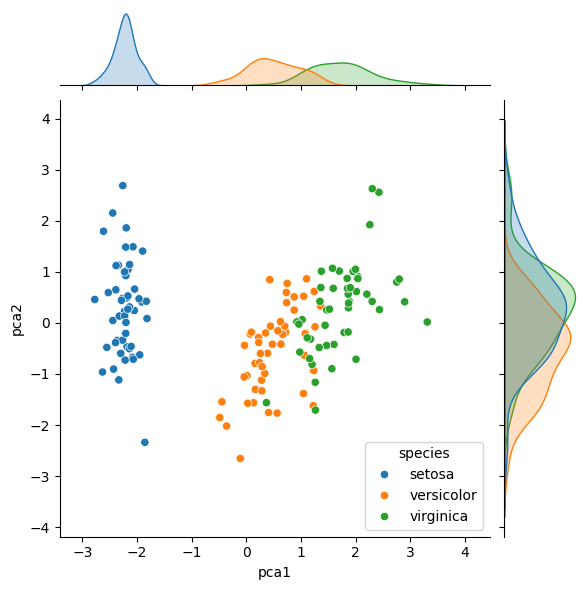

In [40]:
iris['pca1'] = reduced_scaled[:,0]
iris['pca2'] = reduced_scaled[:,1]
sns.jointplot(x=iris['pca1'], y=iris['pca2'], hue=iris['species'])

# CARS DATA FRAME

In [64]:
cars_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/Files/cars.csv')
cars_df

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_fuel,engine_has_gas,engine_type,engine_capacity,...,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,duration_listed
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,False,gasoline,2.5,...,True,True,True,False,True,False,True,True,True,16
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,False,gasoline,3.0,...,True,False,False,True,True,False,False,False,True,83
2,Subaru,Forester,automatic,red,402000,2001,gasoline,False,gasoline,2.5,...,True,False,False,False,False,False,False,True,True,151
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,False,gasoline,3.0,...,False,False,False,False,False,False,False,False,False,86
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,False,gasoline,2.5,...,True,False,True,True,False,False,False,False,True,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
38526,Chrysler,300,automatic,silver,290000,2000,gasoline,False,gasoline,3.5,...,True,False,False,True,True,False,False,True,True,301
38527,Chrysler,PT Cruiser,mechanical,blue,321000,2004,diesel,False,diesel,2.2,...,True,False,False,True,True,False,False,True,True,317
38528,Chrysler,300,automatic,blue,777957,2000,gasoline,False,gasoline,3.5,...,True,False,False,True,True,False,False,True,True,369
38529,Chrysler,PT Cruiser,mechanical,black,20000,2001,gasoline,False,gasoline,2.0,...,True,False,False,False,False,False,False,False,True,490


In [65]:
cars_df.columns

Index(['manufacturer_name', 'model_name', 'transmission', 'color',
       'odometer_value', 'year_produced', 'engine_fuel', 'engine_has_gas',
       'engine_type', 'engine_capacity', 'body_type', 'has_warranty', 'state',
       'drivetrain', 'price_usd', 'is_exchangeable', 'location_region',
       'number_of_photos', 'up_counter', 'feature_0', 'feature_1', 'feature_2',
       'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7',
       'feature_8', 'feature_9', 'duration_listed'],
      dtype='object')

In [72]:
cars_df_clean = cars_df.copy()


cars_df_clean['feature_count'] = cars_df_clean[[f'feature_{i}' for i in range(1, 10)]].sum(axis=1)
cars_df_clean.drop(columns=['engine_has_gas', 'engine_fuel','number_of_photos', 'up_counter', 'feature_0', 'feature_1', 'feature_2',
                            'feature_3', 'feature_4', 'feature_5', 'feature_6', 'feature_7', 'feature_8',
                            'feature_9'], inplace=True)
cars_df_clean.head()

,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_type,engine_capacity,body_type,has_warranty,state,drivetrain,price_usd,is_exchangeable,location_region,duration_listed,feature_count
0,Subaru,Outback,automatic,silver,190000,2010,gasoline,2.5,universal,False,owned,all,10900.00,False,Минская обл.,16,7
1,Subaru,Outback,automatic,blue,290000,2002,gasoline,3.0,universal,False,owned,all,5000.00,True,Минская обл.,83,4
2,Subaru,Forester,automatic,red,402000,2001,gasoline,2.5,suv,False,owned,all,2800.00,True,Минская обл.,151,3
3,Subaru,Impreza,mechanical,blue,10000,1999,gasoline,3.0,sedan,False,owned,all,9999.00,True,Минская обл.,86,0
4,Subaru,Legacy,automatic,black,280000,2001,gasoline,2.5,universal,False,owned,all,2134.11,True,Гомельская обл.,7,4


In [78]:
cars_df_clean.columns

Index(['manufacturer_name', 'model_name', 'transmission', 'color',
       'odometer_value', 'year_produced', 'engine_type', 'engine_capacity',
       'body_type', 'has_warranty', 'state', 'drivetrain', 'price_usd',
       'is_exchangeable', 'location_region', 'duration_listed',
       'feature_count'],
      dtype='object')

In [82]:
!pip install phik

import phik
from phik import report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Select a mix of your numerical and categorical columns
columns_to_study = ['manufacturer_name', 'model_name', 'transmission', 'color',
                    'odometer_value', 'year_produced', 'engine_type', 'engine_capacity',
                    'body_type', 'has_warranty', 'state', 'drivetrain', 'price_usd',
                    'is_exchangeable', 'location_region', 'duration_listed','feature_count'
                    ]

# 2. Slice the dataframe
df_subset = cars_df_clean[columns_to_study]


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 679.7/679.7 kB 12.4 MB/s eta 0:00:00


In [84]:
phik_matrix = df_subset.phik_matrix()
phik_matrix

interval columns not set, guessing: ['odometer_value', 'year_produced', 'engine_capacity', 'price_usd', 'duration_listed', 'feature_count']


/usr/local/lib/python3.12/dist-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable model_name is large: 1118. Are you sure this is not an interval variable? Analysis for pairs of variables including model_name can be slow.
  warnings.warn(


,manufacturer_name,model_name,transmission,color,odometer_value,year_produced,engine_type,engine_capacity,body_type,has_warranty,state,drivetrain,price_usd,is_exchangeable,location_region,duration_listed,feature_count
manufacturer_name,1.000000,0.999980,0.534592,0.344915,0.405622,0.622617,0.426763,0.674895,0.686959,0.620152,0.607363,0.820708,0.450694,0.120372,0.153380,0.152811,0.472815
model_name,0.999980,1.000000,0.796340,0.611940,0.624864,0.920635,0.925174,0.972864,0.967447,0.883643,0.805884,0.983962,0.846323,0.229332,0.221267,0.564124,0.707338
transmission,0.534592,0.796340,1.000000,0.319524,0.321957,0.508019,0.082173,0.551468,0.517111,0.101905,0.044573,0.243753,0.628913,0.041660,0.193203,0.045453,0.704961
color,0.344915,0.611940,0.319524,1.000000,0.205539,0.340875,0.208292,0.172228,0.393524,0.117373,0.148298,0.324267,0.298497,0.038669,0.099697,0.014243,0.286659
odometer_value,0.405622,0.624864,0.321957,0.205539,1.000000,0.640403,0.308395,0.327999,0.280305,0.357972,0.315374,0.257428,0.495177,0.082318,0.121685,0.064978,0.317320
year_produced,0.622617,0.920635,0.508019,0.340875,0.640403,1.000000,0.156723,0.317243,0.293413,0.325601,0.298079,0.347252,0.718696,0.101736,0.190971,0.082466,0.551706
engine_type,0.426763,0.925174,0.082173,0.208292,0.308395,0.156723,1.000000,0.376538,0.555429,0.029052,0.121825,0.202845,0.108389,0.000000,0.081181,0.000000,0.044248
engine_capacity,0.674895,0.972864,0.551468,0.172228,0.327999,0.317243,0.376538,1.000000,0.407106,0.097023,0.095497,0.546377,0.336251,0.103718,0.059363,0.230731,0.447476
body_type,0.686959,0.967447,0.517111,0.393524,0.280305,0.293413,0.555429,0.407106,1.000000,0.136856,0.175806,0.831417,0.361197,0.079733,0.129315,0.061103,0.334511
has_warranty,0.620152,0.883643,0.101905,0.117373,0.357972,0.325601,0.029052,0.097023,0.136856,1.000000,0.574335,0.035369,0.484489,0.183390,0.105111,0.024828,0.196172


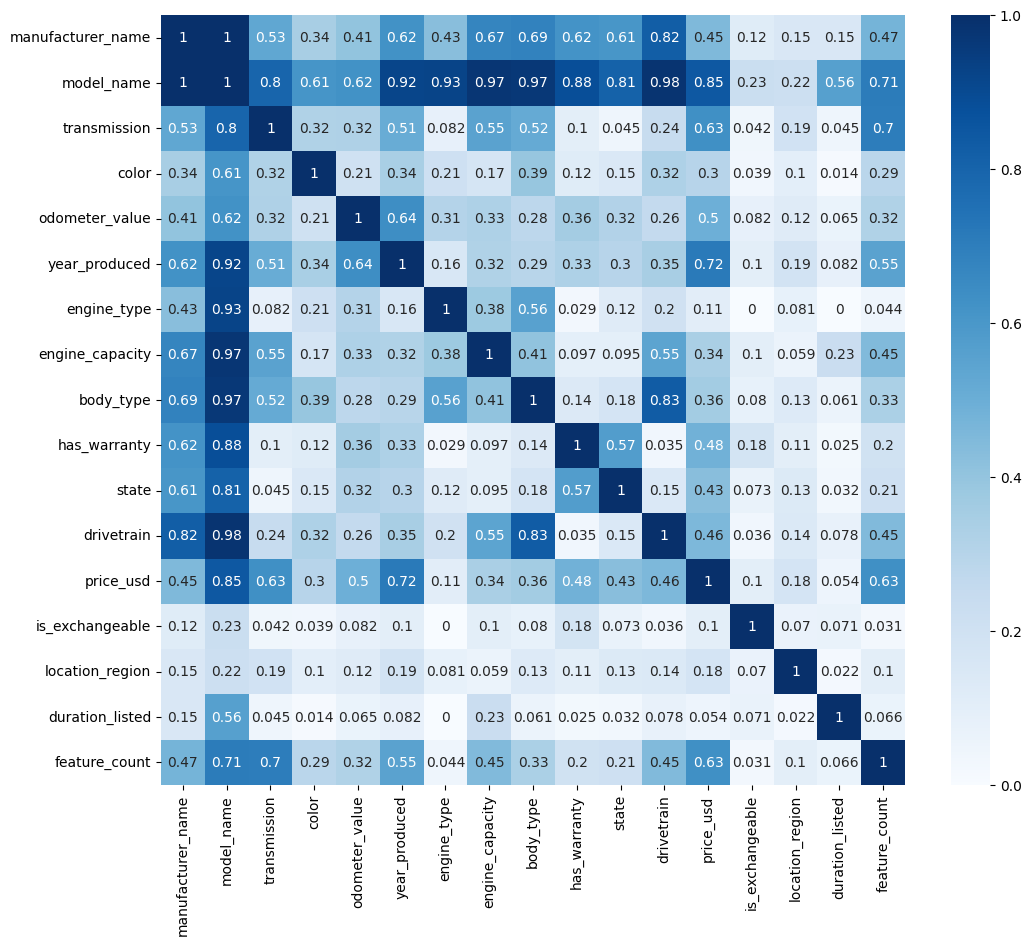

In [111]:
plt.figure(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, cmap='Blues')
plt.show()
#

/tmp/ipykernel_2139/708099940.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=cars_df_clean, x='transmission', y='feature_count', ax=axs[0], palette='Set2')
/tmp/ipykernel_2139/708099940.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_man, x='manufacturer_name', y='feature_count', ax=axs[1], palette='Set2')
/tmp/ipykernel_2139/708099940.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top_mod, x='model_name', y='feature_count', ax=axs[2], palette='Set2')
/tmp/ipykernel_2139/708099940.py:54: FutureWarnin

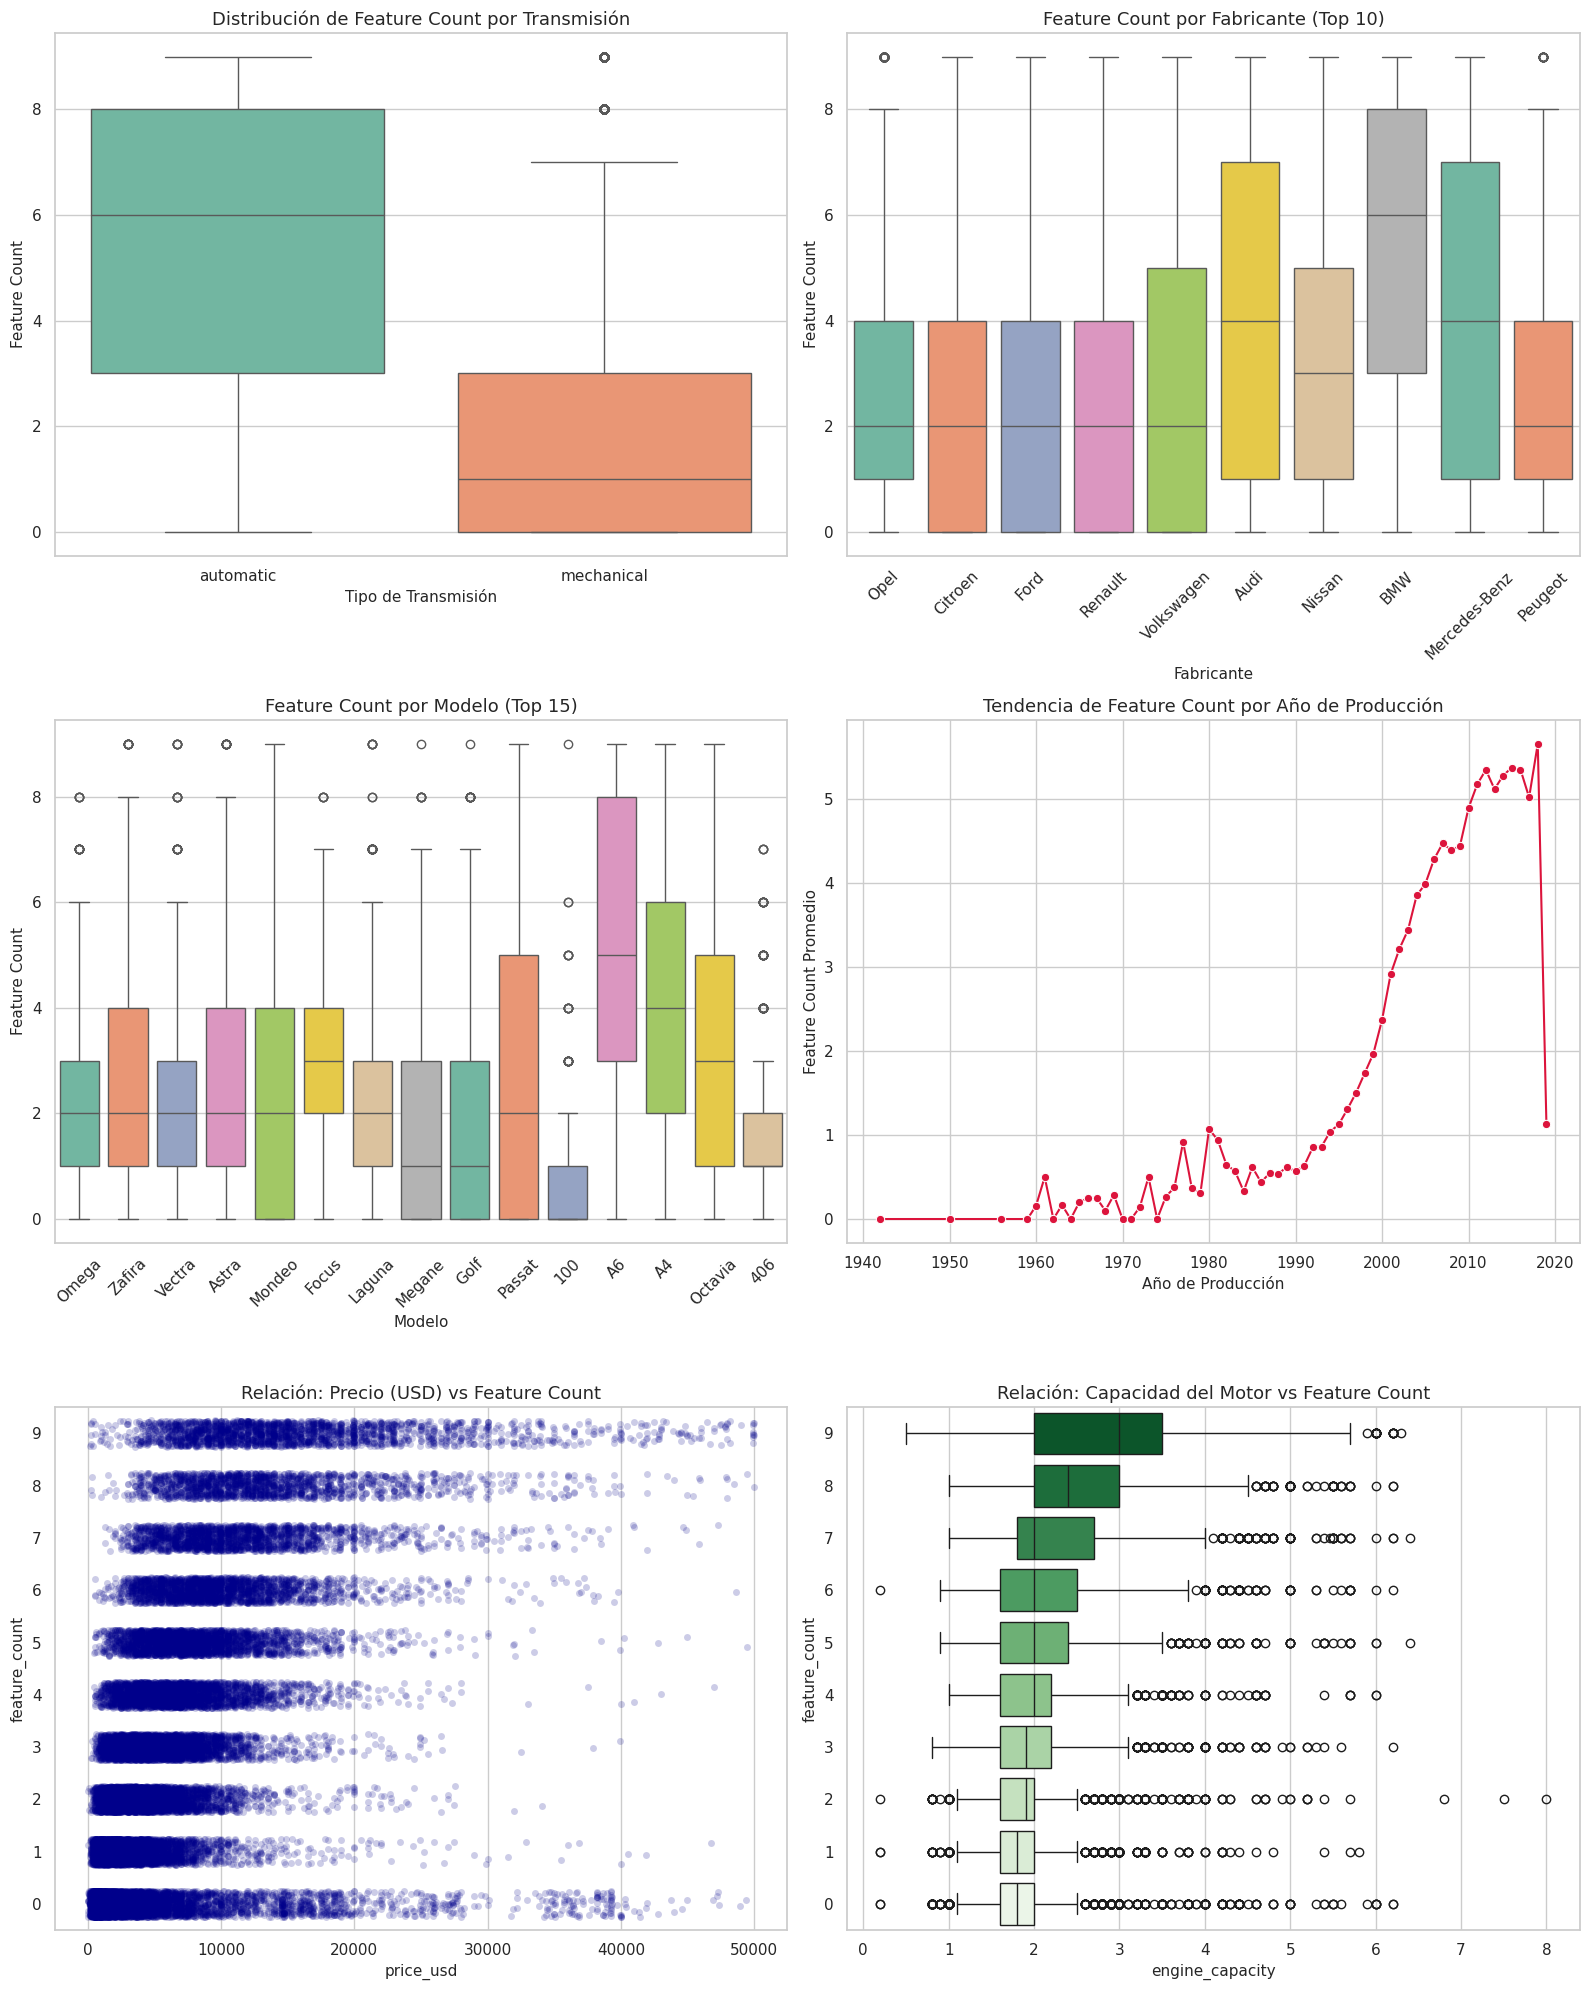

<Figure size 640x480 with 0 Axes>

In [127]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración estética global
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 13})

# 1. Cuadrícula de 3 filas y 2 columnas
fig, axs = plt.subplots(3, 2, figsize=(16, 20))
axs = axs.flatten()

# --- VARIABLES CATEGÓRICAS ---

# Gráfico 0: Transmisión vs Feature Count
sns.boxplot(data=cars_df_clean, x='transmission', y='feature_count', ax=axs[0], palette='Set2')
axs[0].set_title('Distribución de Feature Count por Transmisión')
axs[0].set_xlabel('Tipo de Transmisión')
axs[0].set_ylabel('Feature Count')

# Gráfico 1: Fabricante vs Feature Count (Top 10)
top_manufacturers = cars_df_clean['manufacturer_name'].value_counts().head(10).index
df_top_man = cars_df_clean[cars_df_clean['manufacturer_name'].isin(top_manufacturers)]
sns.boxplot(data=df_top_man, x='manufacturer_name', y='feature_count', ax=axs[1], palette='Set2')
axs[1].set_title('Feature Count por Fabricante (Top 10)')
axs[1].set_xlabel('Fabricante')
axs[1].set_ylabel('Feature Count')
axs[1].tick_params(axis='x', rotation=45)

# Gráfico 2: Modelo vs Feature Count (Top 15)
top_models = cars_df_clean['model_name'].value_counts().head(15).index
df_top_mod = cars_df_clean[cars_df_clean['model_name'].isin(top_models)]
sns.boxplot(data=df_top_mod, x='model_name', y='feature_count', ax=axs[2], palette='Set2')
axs[2].set_title('Feature Count por Modelo (Top 15)')
axs[2].set_xlabel('Modelo')
axs[2].set_ylabel('Feature Count')
axs[2].tick_params(axis='x', rotation=45)

# --- VARIABLES NUMÉRICAS ---

# Gráfico 3: Año de producción (Gráfico de línea para ver la tendencia temporal)
df_year = cars_df_clean.groupby('year_produced')['feature_count'].mean().reset_index()
sns.lineplot(data=df_year, x='year_produced', y='feature_count', ax=axs[3], marker='o', color='crimson')
axs[3].set_title('Tendencia de Feature Count por Año de Producción')
axs[3].set_xlabel('Año de Producción')
axs[3].set_ylabel('Feature Count Promedio')

# Gráfico 4: Precio en USD (Stripplot)
sns.stripplot(data=cars_df_clean, x='price_usd', y='feature_count',
              orient='h', alpha=0.2, jitter=0.25, color='darkblue', ax=axs[4])
axs[4].set_title('Relación: Precio (USD) vs Feature Count')
axs[4].invert_yaxis()

# Gráfico 5: Capacidad del motor (Boxplot)
sns.boxplot(data=cars_df_clean, x='engine_capacity', y='feature_count',
            orient='h', ax=axs[5], palette='Greens')
axs[5].set_title('Relación: Capacidad del Motor vs Feature Count')
axs[5].invert_yaxis()

# Ajustar espacios y mostrar
plt.tight_layout()
plt.show()

# Ajustar espacios para evitar que los textos se pisen
plt.tight_layout()
plt.show()


In [113]:
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

X = cars_df_clean[['model_name', 'transmission', 'manufacturer_name', 'year_produced',
                   'price_usd', 'engine_capacity']].copy()

y = cars_df_clean['feature_count']

categorical_cols = ['model_name', 'transmission', 'manufacturer_name']
for col in categorical_cols:
    X[col] = X[col].astype('category')

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = lgb.LGBMRegressor(objective='poisson', random_state=42)
model.fit(X_train, y_train)

model

[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000600 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1208
[LightGBM] [Info] Number of data points in the train set: 30824, number of used features: 6
[LightGBM] [Info] Start training from score 1.143123


LGBMRegressor(objective='poisson', random_state=42)

In [114]:
predictions = model.predict(X_test)
predictions

array([4.49612441, 3.64826575, 3.79060492, ..., 6.10615881, 6.28498811,
       0.48728466])

In [115]:
mae = mean_absolute_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print(f"Error Medio Absoluto (MAE): {mae:.2f} características")
print(f"Coeficiente de Error (R²): {r2:.2f}")

Error Medio Absoluto (MAE): 1.20 características
Coeficiente de Error (R²): 0.66


# TRIED

In [132]:
new_car = pd.DataFrame([{
    'model_name': 'golf',
    'transmission': 'automatic',
    'manufacturer_name': 'volkswagen',
    'year_produced': 2018,
    'price_usd': 20000,
    'engine_capacity': 1.9
}])

for col in categorical_cols:
  new_car[col] = new_car[col].astype('category')

predicted = model.predict(new_car)
print(f"The posiility features for this car is {predicted[0]:.1f}")

The posiility features for this car is 6.4


In [133]:
# Ver la importancia de las variables
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': model.feature_importances_
}).sort_values(by='Importancia', ascending=False)

print(importancias)


            Variable  Importancia
0         model_name         1202
4          price_usd          614
3      year_produced          404
2  manufacturer_name          391
5    engine_capacity          301
1       transmission           88
